In [1]:
import os
import numpy as np
from numpy.fft import fft2, ifft2, fftshift, ifftshift, fftfreq
import matplotlib.pyplot as plt
from skimage import data
from skimage.transform import resize

os.makedirs("images", exist_ok= True)

---
## Procedural Task #1: Laplacian Filtering in the Frequency Domain
In the frequency domain, the 2D Laplacian derivative operator $\nabla^2 f(x, y)$ corresponds to multiplying the Fourier transform $F(u, v)$ by $-4\pi^2(u^2 + v^2)$.


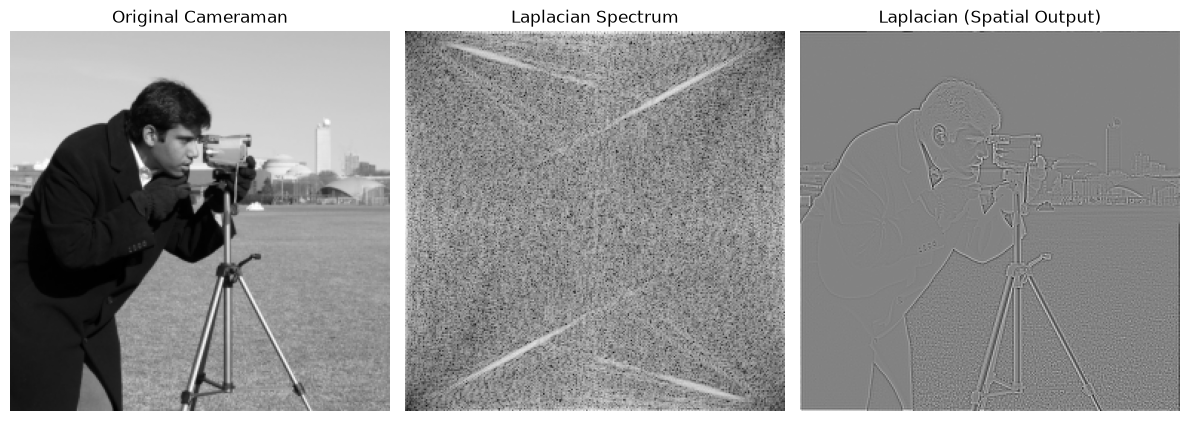

In [2]:
# Load cameraman image (already grayscale) and resize for faster FFT
image= data.camera()
image= resize(image, (256, 256), anti_aliasing= True)

# Save original image for repository submission
plt.imsave("images/cameraman.png", image, cmap= "gray")

# Get image dimensions
M, N = image.shape

# Generate frequency grid
u= fftfreq(M).reshape(-1, 1)
v= fftfreq(N).reshape(1, -1)

# Compute Laplacian filter in frequency domain
laplacian_filter= -4 * (np.pi ** 2) * (u**2 + v**2)

# Apply 2D FFT to the image
F= fft2(image)

# Apply Laplacian filter in frequency domain
F_lap= F * laplacian_filter

# Inverse FFT to obtain spatial result
laplacian_image= ifft2(F_lap).real

# Plot results
plt.figure(figsize= (12, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap= "gray")
plt.title("Original Cameraman")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(np.log(1 + np.abs(F_lap)), cmap= "gray")
plt.title("Laplacian Spectrum")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(laplacian_image, cmap= "gray")
plt.title("Laplacian (Spatial Output)")
plt.axis("off")

plt.tight_layout()
plt.savefig("images/task1_laplacian_results.png", dpi= 300, bbox_inches= "tight")
plt.show()

---
## Assessment Task #1: Sobel Filtering in the Frequency Domain
By the Convolution Theorem, spatial convolution is equivalent to point-wise multiplication in the frequency domain:
$$g(x, y) = f(x, y) * h(x, y) \iff G(u, v) = F(u, v) \cdot H(u, v)$$
To prevent circular convolution artifacts and phase offsets, the $3 \times 3$ Sobel kernels are zero-padded to match the $256 \times 256$ image dimensions, centered, and shifted via `ifftshift` so the kernel origin $(0,0)$ aligns with the top-left corner prior to computing the 2D FFT.


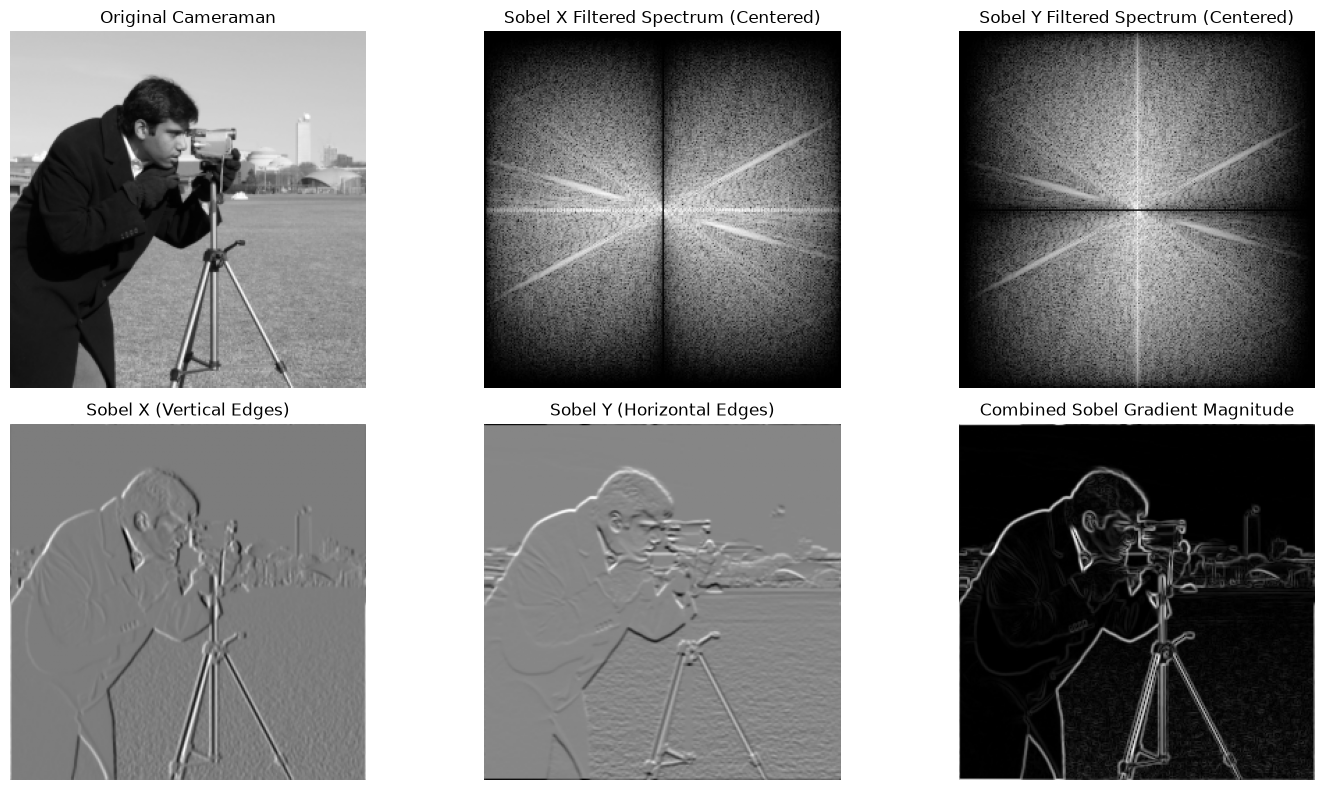

In [3]:
# Define 3x3 Sobel filters for vertical (X) and horizontal (Y) edge detection
sobel_x= np.array([[-1, 0, 1],
                   [-2, 0, 2],
                   [-1, 0, 1]])

sobel_y= np.array([[-1, -2, -1],
                   [ 0,  0,  0],
                   [ 1,  2,  1]])

# Proper padding and centering of kernel in spatial domain
def center_embed_kernel(kernel, shape):
    padded= np.zeros(shape)
    
    kh, kw = kernel.shape
    ph, pw = shape
    cy, cx = ph // 2, pw // 2 # Find center coordinates
    
    padded[cy - kh//2:cy - kh//2 + kh, cx - kw//2:cx - kw//2 + kw]= kernel # Insert kernel centered at the image center
    return fft2(ifftshift(padded))  # Shift before FFT to place (0,0) at top-left

# Compute 2D FFT of the image
F= fft2(image)

# Compute FFT of centered Sobel filters
H_sobel_x= center_embed_kernel(sobel_x, image.shape)
H_sobel_y= center_embed_kernel(sobel_y, image.shape)

# Multiply in the frequency domain
F_sobel_x= F * H_sobel_x
F_sobel_y= F * H_sobel_y

# Compute Inverse FFT to get spatial domain filtered images
sobel_x_spatial= ifft2(F_sobel_x).real
sobel_y_spatial= ifft2(F_sobel_y).real

# Compute Combined Sobel Gradient Magnitude
sobel_magnitude= np.hypot(sobel_x_spatial, sobel_y_spatial)

# Plot Frequency Spectra and Spatial Outputs
plt.figure(figsize= (15, 8))

# Row 1: Original & Frequency Spectra
plt.subplot(2, 3, 1)
plt.imshow(image, cmap= "gray")
plt.title("Original Cameraman")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(np.log(1 + np.abs(fftshift(F_sobel_x))), cmap= "gray")
plt.title("Sobel X Filtered Spectrum (Centered)")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(np.log(1 + np.abs(fftshift(F_sobel_y))), cmap= "gray")
plt.title("Sobel Y Filtered Spectrum (Centered)")
plt.axis("off")

# Row 2: Spatial Domain Outputs
plt.subplot(2, 3, 4)
plt.imshow(sobel_x_spatial, cmap= "gray")
plt.title("Sobel X (Vertical Edges)")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(sobel_y_spatial, cmap= "gray")
plt.title("Sobel Y (Horizontal Edges)")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(sobel_magnitude, cmap= "gray")
plt.title("Combined Sobel Gradient Magnitude")
plt.axis("off")

plt.tight_layout()
plt.savefig("images/assessment_sobel_results.png", dpi= 300, bbox_inches= "tight")
plt.show()